# 01 · Tratamento dos dados

**Responsável:** P2 – Dados & Repositório

**Objetivo:** validar a base bruta, documentar as inconsistências encontradas e gerar a base tratada usada por todos os outros notebooks.

| | Arquivo |
|---|---|
| Entrada | `data/raw/desafio_nps_fase_1.csv` (nunca é alterado) |
| Saída | `data/processed/nps_tratado.csv` |
| Figura | `reports/figures/distribuicao_nps.png` |

**Etapas:** carga → tipos → nulos → duplicados → faixas válidas → consistência entre variáveis → outliers → variáveis criadas → exportação.

As premissas de negócio usadas aqui estão na seção 7 do README.

## 0. Configuração

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Caminhos relativos à raiz do repositório (o notebook roda de dentro de notebooks/)
ROOT = Path.cwd().parent
RAW_PATH = ROOT / "data" / "raw" / "desafio_nps_fase_1.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "nps_tratado.csv"
FIGURES_DIR = ROOT / "reports" / "figures"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
# Estilo padrão dos gráficos do projeto: fundo claro, grade discreta e texto em cinza
COR_SERIE = "#2a78d6"
COR_TEXTO = "#0b0b0b"
COR_TEXTO_SECUNDARIO = "#52514e"
COR_TEXTO_MUDO = "#898781"
COR_GRADE = "#e1e0d9"
COR_EIXO = "#c3c2b7"
COR_FUNDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COR_FUNDO,
    "axes.facecolor": COR_FUNDO,
    "axes.edgecolor": COR_EIXO,
    "axes.labelcolor": COR_TEXTO_SECUNDARIO,
    "axes.titlecolor": COR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": COR_TEXTO_SECUNDARIO,
    "ytick.color": COR_TEXTO_SECUNDARIO,
    "font.size": 10,
})

## 1. Carga da base bruta

`df_raw` guarda a base exatamente como veio. Todo o tratamento é feito em uma cópia (`df`).

In [3]:
df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()

print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas".replace(",", "."))
df.head()

2.500 linhas x 19 colunas


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.90,0,3,6.50
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.40,0,3,0.00
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.80,0,7,1.50
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.90,0,4,0.30
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.10,0,3,7.90


## 2. Tipos de dados

Cada coluna é comparada com o tipo esperado pelo dicionário de dados do README. Identificadores e contagens devem ser inteiros, valores monetários e notas podem ter casas decimais e a região é texto.

In [4]:
# Tipo esperado por grupo de colunas (dicionário de dados do README)
COLUNAS_ID = ["customer_id", "order_id"]
COLUNAS_INTEIRAS = [
    "customer_age", "customer_tenure_months", "items_quantity", "payment_installments",
    "delivery_time_days", "delivery_delay_days", "delivery_attempts",
    "customer_service_contacts", "resolution_time_days", "complaints_count", "repeat_purchase_30d",
]
COLUNAS_DECIMAIS = ["order_value", "discount_value", "freight_value", "nps_score", "csat_internal_score"]
COLUNAS_TEXTO = ["customer_region"]


def tipo_esperado(coluna):
    if coluna in COLUNAS_ID or coluna in COLUNAS_INTEIRAS:
        return "inteiro"
    if coluna in COLUNAS_DECIMAIS:
        return "decimal"
    return "texto"


def tipo_confere(serie, esperado):
    if esperado == "inteiro":
        return pd.api.types.is_integer_dtype(serie)
    if esperado == "decimal":
        return pd.api.types.is_numeric_dtype(serie)
    return not pd.api.types.is_numeric_dtype(serie)


tipos = pd.DataFrame({
    "tipo_lido": df.dtypes.astype(str),
    "tipo_esperado": [tipo_esperado(c) for c in df.columns],
})
tipos["confere"] = [tipo_confere(df[c], tipos.loc[c, "tipo_esperado"]) for c in df.columns]

print("Colunas fora do tipo esperado:", (~tipos["confere"]).sum())
tipos

Colunas fora do tipo esperado: 0


,tipo_lido,tipo_esperado,confere
customer_id,int64,inteiro,True
customer_age,int64,inteiro,True
customer_region,str,texto,True
customer_tenure_months,int64,inteiro,True
order_id,int64,inteiro,True
order_value,float64,decimal,True
items_quantity,int64,inteiro,True
discount_value,float64,decimal,True
payment_installments,int64,inteiro,True
delivery_time_days,int64,inteiro,True


In [5]:
# Padroniza o texto da região (remove espaços nas pontas) e confere as categorias
df["customer_region"] = df["customer_region"].str.strip()
df["customer_region"].value_counts()

customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

## 3. Valores nulos

In [6]:
nulos = df.isna().sum()

# Texto vazio também conta como ausência de informação
nulos["customer_region"] += (df["customer_region"] == "").sum()

print("Total de valores ausentes:", nulos.sum())
nulos[nulos > 0]

Total de valores ausentes: 0


Series([], dtype: int64)

## 4. Duplicados

In [7]:
duplicados = {
    "linhas idênticas": df.duplicated().sum(),
    "customer_id repetido": df["customer_id"].duplicated().sum(),
    "order_id repetido": df["order_id"].duplicated().sum(),
}
for verificacao, quantidade in duplicados.items():
    print(f"{verificacao}: {quantidade}")

# Se aparecerem linhas idênticas em uma nova versão da base, elas são removidas aqui
df = df.drop_duplicates()

linhas idênticas: 0
customer_id repetido: 0
order_id repetido: 0


## 5. Faixas válidas

Valores fora da faixa possível indicam erro de registro (ex.: idade negativa ou nota acima de 10).

In [8]:
# (mínimo, máximo) aceitos para cada coluna; None = sem limite
FAIXAS_VALIDAS = {
    "customer_age": (18, 100),
    "customer_tenure_months": (0, None),
    "order_value": (0, None),
    "items_quantity": (1, None),
    "discount_value": (0, None),
    "payment_installments": (1, None),
    "delivery_time_days": (0, None),
    "delivery_delay_days": (0, None),
    "freight_value": (0, None),
    "delivery_attempts": (1, None),
    "customer_service_contacts": (0, None),
    "resolution_time_days": (0, None),
    "nps_score": (0, 10),
    "repeat_purchase_30d": (0, 1),
    "complaints_count": (0, None),
    "csat_internal_score": (0, 10),
}
REGIOES_VALIDAS = {"Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"}

linhas = []
for coluna, (minimo, maximo) in FAIXAS_VALIDAS.items():
    fora = pd.Series(False, index=df.index)
    if minimo is not None:
        fora |= df[coluna] < minimo
    if maximo is not None:
        fora |= df[coluna] > maximo
    linhas.append({
        "coluna": coluna,
        "mínimo aceito": minimo,
        "máximo aceito": maximo,
        "mínimo observado": df[coluna].min(),
        "máximo observado": df[coluna].max(),
        "registros fora": int(fora.sum()),
    })

faixas = pd.DataFrame(linhas).set_index("coluna")
print("Registros fora da faixa:", faixas["registros fora"].sum())
print("Regiões fora da lista:", (~df["customer_region"].isin(REGIOES_VALIDAS)).sum())
faixas

Registros fora da faixa: 0
Regiões fora da lista: 0


,mínimo aceito,máximo aceito,mínimo observado,máximo observado,registros fora
coluna,,,,,
customer_age,18,100.00,18.00,69.00,0
customer_tenure_months,0,NaN,1.00,119.00,0
order_value,0,NaN,7.76,1983.81,0
items_quantity,1,NaN,1.00,6.00,0
discount_value,0,NaN,0.02,230.33,0
payment_installments,1,NaN,1.00,11.00,0
delivery_time_days,0,NaN,2.00,14.00,0
delivery_delay_days,0,NaN,0.00,8.00,0
freight_value,0,NaN,2.62,76.13,0


## 6. Consistência entre variáveis

Aqui os valores estão dentro da faixa, mas a combinação entre duas colunas chama atenção. Nenhum registro é removido: os casos são marcados com colunas `flag_*` para que a EDA e o modelo possam considerá-los.

### 6.1 Atraso maior que o prazo de entrega

Pela orientação do professor (premissa 7.1 do README), `delivery_time_days` é o **prazo previsto** e `delivery_delay_days` é o **atraso** sobre esse prazo. Com essa leitura, um atraso maior que o prazo é possível: um pedido com prazo de 3 dias e 5 de atraso levou 8 dias para chegar.

In [9]:
atraso_maior_que_prazo = df["delivery_delay_days"] > df["delivery_time_days"]
print("Pedidos com atraso maior que o prazo:", atraso_maior_que_prazo.sum())

df.loc[atraso_maior_que_prazo, ["order_id", "delivery_time_days", "delivery_delay_days"]].head()

Pedidos com atraso maior que o prazo: 121


,order_id,delivery_time_days,delivery_delay_days
5,50006,4,5
18,50019,3,4
41,50042,2,3
46,50047,4,6
58,50059,2,3


### 6.2 Desconto maior que o valor do pedido

Se `order_value` for o valor **já com o desconto aplicado**, um desconto maior que o valor pago é possível (ex.: pedido de R$ 140,91 com R$ 99,62 de desconto, pago por R$ 41,29). Como o dicionário não esclarece, os pedidos são mantidos e marcados com `flag_discount_over_order_value`.

In [10]:
df["flag_discount_over_order_value"] = (df["discount_value"] > df["order_value"]).astype(int)
print("Pedidos com desconto maior que o valor:", df["flag_discount_over_order_value"].sum())

df.loc[df["flag_discount_over_order_value"] == 1, ["order_id", "order_value", "discount_value"]].head()

Pedidos com desconto maior que o valor: 35


,order_id,order_value,discount_value
6,50007,41.29,99.62
57,50058,86.15,112.42
116,50117,60.96,95.06
182,50183,24.00,85.49
270,50271,79.93,129.11


### 6.3 Tempo de resolução sem contato com o atendimento

Pedidos com `resolution_time_days > 0` e nenhum contato com o atendimento. Uma explicação possível é que o tempo de resolução se refira a reclamações abertas por outro canal. Os pedidos são mantidos e marcados com `flag_resolution_without_contact`.

In [11]:
resolucao_sem_contato = (df["resolution_time_days"] > 0) & (df["customer_service_contacts"] == 0)
df["flag_resolution_without_contact"] = resolucao_sem_contato.astype(int)

print("Pedidos com resolução sem contato:", resolucao_sem_contato.sum())
print(f"Desses, com pelo menos uma reclamação: {(df.loc[resolucao_sem_contato, 'complaints_count'] > 0).mean():.0%}")

Pedidos com resolução sem contato: 511
Desses, com pelo menos uma reclamação: 96%


## 7. Outliers

Critério do intervalo interquartil (IQR): valores abaixo de Q1 − 1,5×IQR ou acima de Q3 + 1,5×IQR. A variável alvo (`nps_score`), os identificadores e as colunas de vazamento ficam de fora.

In [12]:
COLUNAS_OUTLIERS = [
    "customer_age", "customer_tenure_months", "order_value", "items_quantity", "discount_value",
    "payment_installments", "delivery_time_days", "delivery_delay_days", "freight_value",
    "delivery_attempts", "customer_service_contacts", "resolution_time_days", "complaints_count",
]

linhas = []
for coluna in COLUNAS_OUTLIERS:
    q1, q3 = df[coluna].quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = (df[coluna] < limite_inferior) | (df[coluna] > limite_superior)
    linhas.append({
        "coluna": coluna,
        "limite inferior": limite_inferior,
        "limite superior": limite_superior,
        "máximo observado": df[coluna].max(),
        "outliers": int(fora.sum()),
        "% da base": fora.mean() * 100,
    })

outliers = pd.DataFrame(linhas).set_index("coluna").sort_values("outliers", ascending=False)
outliers

,limite inferior,limite superior,máximo observado,outliers,% da base
coluna,,,,,
customer_service_contacts,-0.50,3.50,7.00,176,7.04
discount_value,-39.04,88.75,230.33,125,5.00
order_value,-315.32,1112.86,1983.81,84,3.36
complaints_count,0.00,8.00,11.00,29,1.16
delivery_delay_days,-2.00,6.00,8.00,17,0.68
freight_value,5.41,70.78,76.13,12,0.48
items_quantity,-2.50,9.50,6.00,0,0.00
customer_age,-6.50,93.50,69.00,0,0.00
customer_tenure_months,-59.00,181.00,119.00,0,0.00


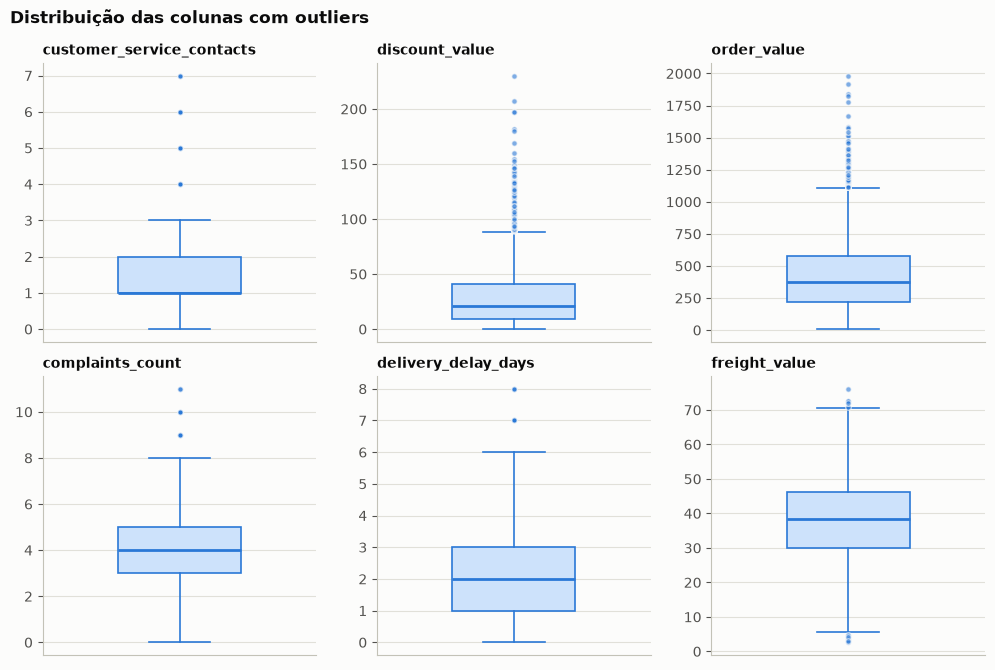

In [13]:
# Boxplots só das colunas que têm outliers
colunas_com_outliers = outliers.index[outliers["outliers"] > 0].tolist()

n_colunas = 3
n_linhas = int(np.ceil(len(colunas_com_outliers) / n_colunas))
fig, eixos = plt.subplots(n_linhas, n_colunas, figsize=(10, 3.4 * n_linhas), squeeze=False)
for eixo in eixos.flat[len(colunas_com_outliers):]:
    eixo.set_visible(False)

for eixo, coluna in zip(eixos.flat, colunas_com_outliers):
    eixo.boxplot(
        df[coluna], widths=0.45, patch_artist=True,
        boxprops={"facecolor": "#cde2fb", "edgecolor": COR_SERIE, "linewidth": 1.2},
        medianprops={"color": COR_SERIE, "linewidth": 2},
        whiskerprops={"color": COR_SERIE, "linewidth": 1.2},
        capprops={"color": COR_SERIE, "linewidth": 1.2},
        flierprops={"marker": "o", "markersize": 4, "markerfacecolor": COR_SERIE,
                    "markeredgecolor": COR_FUNDO, "alpha": 0.6},
    )
    eixo.set_title(coluna, fontsize=10)
    eixo.set_xticks([])
    eixo.grid(axis="x", visible=False)

fig.suptitle("Distribuição das colunas com outliers", x=0.01, ha="left", fontweight="bold", color=COR_TEXTO)
fig.tight_layout()
plt.show()

**Decisão:** os outliers são **mantidos**. Todos estão dentro de faixas possíveis (seção 5) e representam pedidos reais de maior valor ou com mais desconto e frete, que interessam ao negócio. Remover essas linhas esconderia exatamente os casos extremos da experiência. Se o modelo usar algoritmos sensíveis a escala (ex.: regressão linear), a padronização será feita no pipeline do notebook 04.

## 8. Variáveis criadas

| Variável | Regra |
|---|---|
| `nps_category` | Detrator (nota < 7), Neutro (7 ≤ nota < 9), Promotor (nota ≥ 9) |
| `is_detractor` | 1 se a categoria for Detrator |
| `total_delivery_days` | prazo previsto + atraso = tempo real até a entrega |
| `is_late` | 1 se houve atraso |

As notas têm casas decimais, então a categoria usa **intervalos** em vez de notas inteiras (premissa 7.2 do README).

In [14]:
ORDEM_CATEGORIAS = ["Detrator", "Neutro", "Promotor"]

# right=False: cada faixa inclui o limite inferior e exclui o superior -> [0, 7), [7, 9), [9, 10]
df["nps_category"] = pd.cut(
    df["nps_score"],
    bins=[0, 7, 9, np.inf],
    labels=ORDEM_CATEGORIAS,
    right=False,
)
df["is_detractor"] = (df["nps_category"] == "Detrator").astype(int)
df["total_delivery_days"] = df["delivery_time_days"] + df["delivery_delay_days"]
df["is_late"] = (df["delivery_delay_days"] > 0).astype(int)

print("Notas sem categoria:", df["nps_category"].isna().sum())

# Conferência: as notas mínima e máxima de cada categoria respeitam os limites
df.groupby("nps_category", observed=True)["nps_score"].agg(["count", "min", "max"])

Notas sem categoria: 0


,count,min,max
nps_category,,,
Detrator,2109,0.00,6.90
Neutro,281,7.00,8.90
Promotor,110,9.00,10.00


In [15]:
distribuicao = df["nps_category"].value_counts(normalize=True).reindex(ORDEM_CATEGORIAS) * 100
nps_geral = distribuicao["Promotor"] - distribuicao["Detrator"]

for categoria, percentual in distribuicao.items():
    print(f"{categoria:<9} {percentual:5.1f}%")
print(f"\nNPS geral da base: {nps_geral:.0f}")

Detrator   84.4%
Neutro     11.2%
Promotor    4.4%

NPS geral da base: -80


### 8.1 Sensibilidade da regra de categorização

Se a nota fosse arredondada antes de categorizar (ex.: 6,5 → 7), parte dos clientes mudaria de categoria. O número abaixo ajuda o grupo (P1 e P2) a validar a regra adotada.

In [16]:
# Arredondamento comercial (0,5 sobe), diferente do round() do Python, que arredonda para o par
nota_arredondada = np.floor(df["nps_score"] + 0.5)
categoria_arredondada = pd.cut(nota_arredondada, bins=[0, 7, 9, np.inf], labels=ORDEM_CATEGORIAS, right=False)

mudariam = (categoria_arredondada != df["nps_category"])
print(f"Clientes que mudariam de categoria com arredondamento: {mudariam.sum()} ({mudariam.mean():.1%})")
pd.crosstab(df["nps_category"], categoria_arredondada, rownames=["regra adotada"], colnames=["com arredondamento"])

Clientes que mudariam de categoria com arredondamento: 180 (7.2%)


com arredondamento,Detrator,Neutro,Promotor
regra adotada,,,
Detrator,1975,134,0
Neutro,0,235,46
Promotor,0,0,110


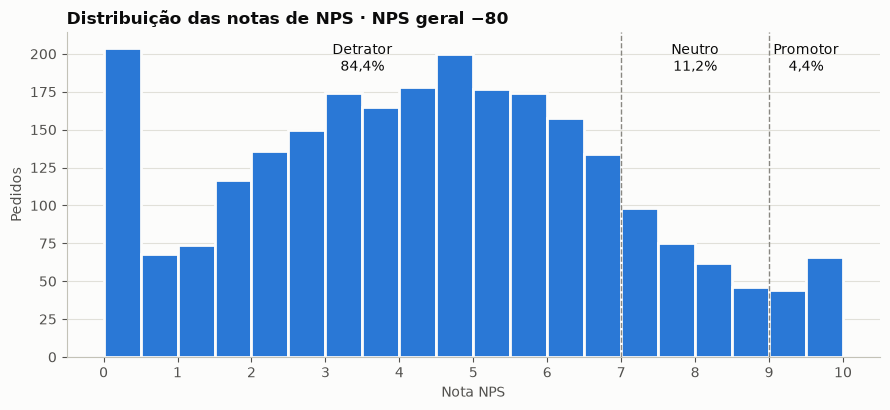

In [17]:
# Distribuição das notas com os limites de cada categoria
fig, eixo = plt.subplots(figsize=(9, 4.2))
eixo.hist(df["nps_score"], bins=np.arange(0, 10.5, 0.5), color=COR_SERIE, edgecolor=COR_FUNDO, linewidth=2)

for limite in (7, 9):
    eixo.axvline(limite, color=COR_TEXTO_MUDO, linestyle="--", linewidth=1)

altura = eixo.get_ylim()[1]
posicoes = {"Detrator": 3.5, "Neutro": 8, "Promotor": 9.5}
for categoria, x in posicoes.items():
    eixo.text(x, altura * 0.97, f"{categoria}\n{distribuicao[categoria]:.1f}%".replace(".", ","),
              ha="center", va="top", color=COR_TEXTO, fontsize=10)

eixo.set_title(f"Distribuição das notas de NPS · NPS geral {nps_geral:.0f}".replace("-", "−"))
eixo.set_xlabel("Nota NPS")
eixo.set_ylabel("Pedidos")
eixo.set_xticks(range(0, 11))
eixo.grid(axis="x", visible=False)
fig.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES_DIR / "distribuicao_nps.png", dpi=150)
plt.show()

## 9. Exportação da base tratada

A base tratada mantém todas as colunas originais e acrescenta as variáveis criadas e as flags.

In [18]:
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)

# Conferência: relê o arquivo salvo e compara com o DataFrame tratado
conferencia = pd.read_csv(PROCESSED_PATH)
assert conferencia.shape == df.shape
assert conferencia["nps_category"].isna().sum() == 0

print(f"Arquivo salvo: {PROCESSED_PATH.relative_to(ROOT).as_posix()}")
print(f"{conferencia.shape[0]:,} linhas x {conferencia.shape[1]} colunas".replace(",", "."))
print("Colunas novas:", [c for c in conferencia.columns if c not in df_raw.columns])

Arquivo salvo: data/processed/nps_tratado.csv
2.500 linhas x 25 colunas
Colunas novas: ['flag_discount_over_order_value', 'flag_resolution_without_contact', 'nps_category', 'is_detractor', 'total_delivery_days', 'is_late']


## 10. Resumo do tratamento

Valores desta versão da base (`desafio_nps_fase_1.csv`, 2.500 pedidos):

| Verificação | Resultado | Decisão |
|---|---|---|
| Tipos de dados | 19 colunas no tipo esperado | Nenhuma conversão necessária |
| Valores nulos | 0 | — |
| Duplicados (linhas, `customer_id`, `order_id`) | 0 | — |
| Faixas válidas | 0 registros fora da faixa | — |
| Atraso maior que o prazo | 121 pedidos | Mantidos: coerente com a premissa prazo previsto + atraso |
| Desconto maior que o valor do pedido | 35 pedidos | Mantidos e marcados em `flag_discount_over_order_value` |
| Resolução sem contato com o atendimento | 511 pedidos (96% com reclamação) | Mantidos e marcados em `flag_resolution_without_contact` |
| Outliers (IQR) | 6 colunas, de 0,5% a 7% da base | Mantidos: valores possíveis e relevantes para o negócio |
| Categoria NPS | 84,4% detratores · 11,2% neutros · 4,4% promotores · **NPS −80** | Regra por intervalos; arredondar a nota mudaria 180 clientes (7,2%) |

**Base tratada:** `data/processed/nps_tratado.csv`, com 2.500 linhas e 25 colunas (19 originais + 6 novas).

### Como usar a base nos próximos notebooks

```python
df = pd.read_csv(ROOT / "data" / "processed" / "nps_tratado.csv")

# O CSV não guarda a ordem das categorias: reaplique para os gráficos saírem na ordem certa
df["nps_category"] = pd.Categorical(
    df["nps_category"], categories=["Detrator", "Neutro", "Promotor"], ordered=True
)
```

> `csat_internal_score` e `repeat_purchase_30d` continuam na base para a EDA, mas **não** entram como variáveis de entrada do modelo (vazamento, seção 7.3 do README).